## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Geethan Sundaram

**Date:** 10/12/2026

In [72]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd

print("-- Q1.1 - Create Datasets --")

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

print(df0_125.head())
print(df0_25.head())
print(df0_5.head())
print(df1_0.head())
print(df2_0.head())

# Put datasets into dictionary
datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}

-- Q1.1 - Create Datasets --
         x1        x2 group
0  0.781279  0.851498     a
1  1.042835  0.931282     a
2  1.144129  0.882494     a
3  0.968445  0.896508     a
4  1.122665  1.013608     a
         x1        x2 group
0  0.562559  0.702996     a
1  1.085670  0.862563     a
2  1.288259  0.764988     a
3  0.936891  0.793017     a
4  1.245330  1.027216     a
         x1        x2 group
0  0.125117  0.405991     a
1  1.171340  0.725127     a
2  1.576518  0.529977     a
3  0.873782  0.586034     a
4  1.490660  1.054432     a
         x1        x2 group
0 -0.749765 -0.188018     a
1  1.342680  0.450254     a
2  2.153036  0.059954     a
3  0.747564  0.172068     a
4  1.981321  1.108863     a
         x1        x2 group
0 -2.499531 -1.376035     a
1  1.685361 -0.099492     a
2  3.306072 -0.880092     a
3  0.495128 -0.655865     a
4  2.962642  1.217727     a


-- Q1.2 - Scatterplots of (X1,X2) points by group for each dataset --


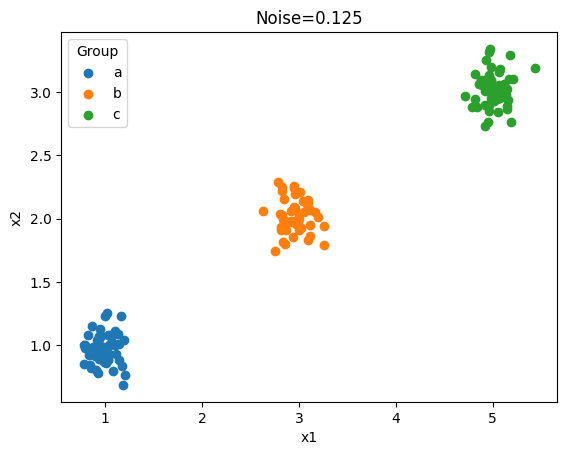

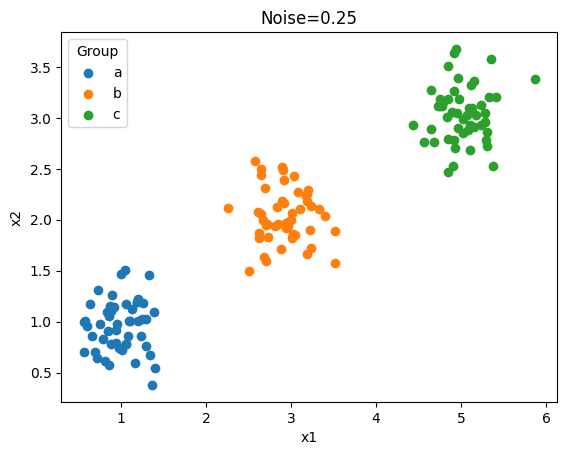

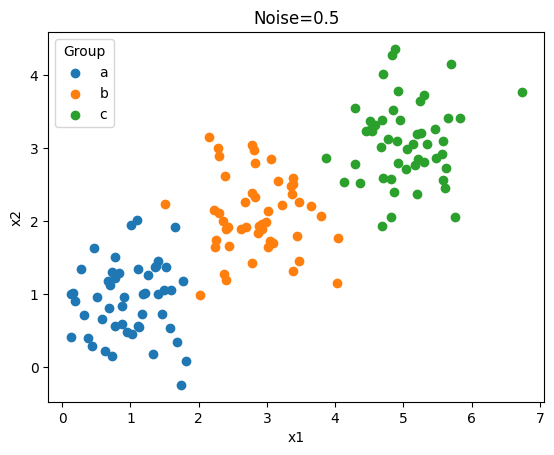

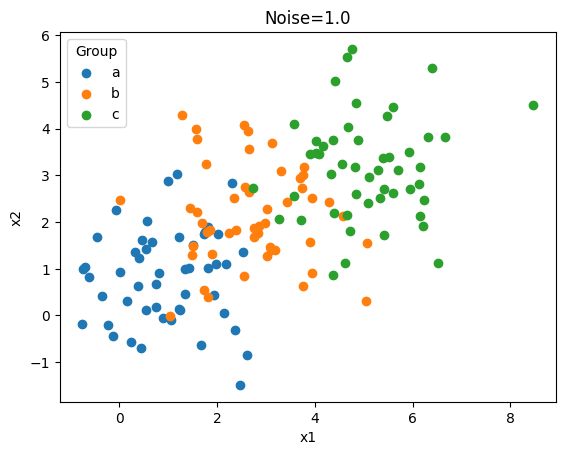

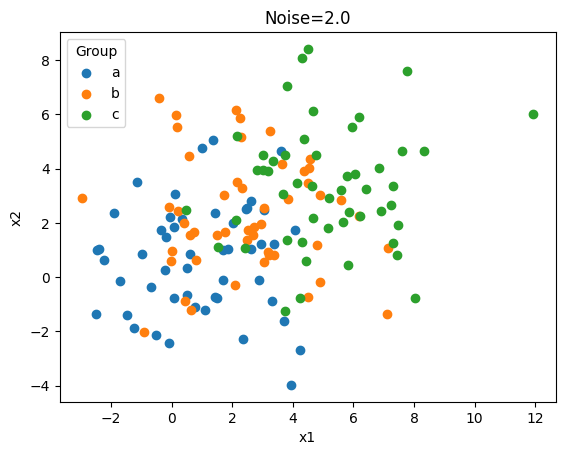

As the noise increases, the clusters become much less distinct and isolated and
the points from the different clusters start to overlap. This makes it way
harder to properly identify the clusters and what separates them.


In [73]:
import matplotlib.pyplot as plt
import textwrap
from sklearn.cluster import KMeans

print("-- Q1.2 - Scatterplots of (X1,X2) points by group for each dataset --")

# Create scatterplots of (X1,X2) points by group for each dataset
for noise, df in datasets.items():
    colors = {'a': 'tab:blue', 'b': 'tab:orange', 'c': 'tab:green'}
    
    for group, group_df in df.groupby('group'):
        plt.scatter(
            group_df['x1'],
            group_df['x2'],
            color=colors[group],
            label=group
        )

    plt.title(f'Noise={noise}')
    plt.xlabel('x1')
    plt.ylabel('x2')
    plt.legend(title='Group')
    plt.show()

text = "As the noise increases, the clusters become much less distinct and isolated and the points from the different clusters start to overlap. This makes it way harder to properly identify the clusters and what separates them."
print("\n".join(textwrap.wrap(text, width=80)))

-- Q1.3 - Scree plots --


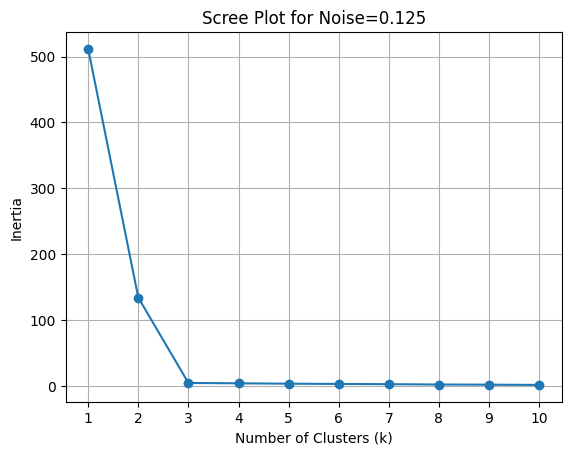

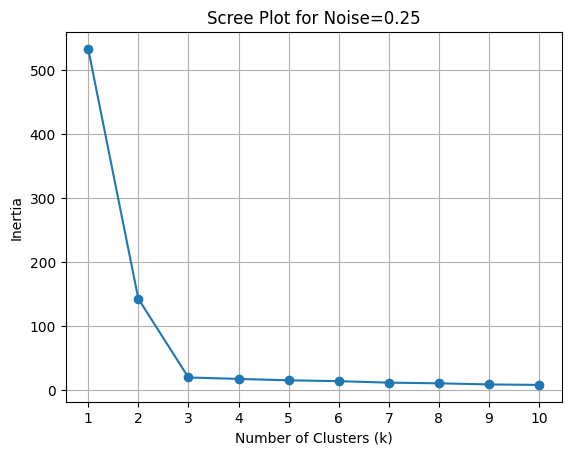

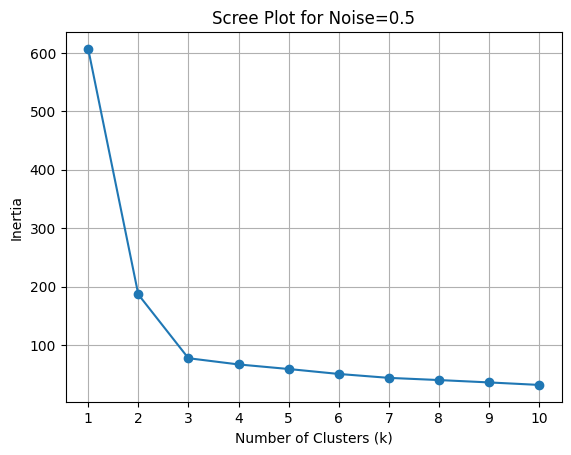

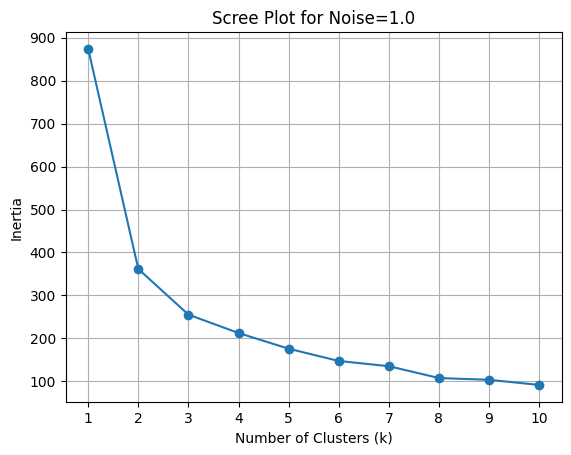

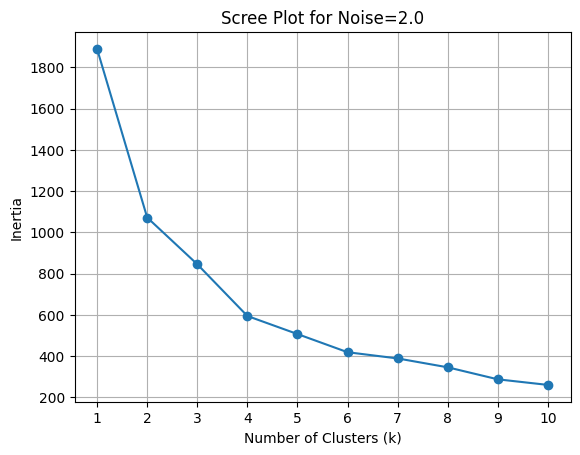

As the noise increases, the scree plots the elbow becomes less noticeable and
the inertia values decreases in a more gradual fashion. The inertia values are
also higher with higher noise levels, which indicates that clusters are less
compact and more spread out instead. Once again, this makes it difficult to
determine the optimal number of clusters without a clear elbow. For selecting a
k-value, it becomes more subjective and less reliable as the noise increases,
since the elbow is used for determining what the k-value is.


In [74]:
print("-- Q1.3 - Scree plots --")

# Create scree plots for each dataset
for noise, df in datasets.items():
    X = df[['x1', 'x2']].values
    inertia = []
    k_values = range(1, 11)

    for k in k_values:
        kmeans = KMeans(n_clusters=k, random_state=100)
        kmeans.fit(X)
        inertia.append(kmeans.inertia_)

    plt.plot(k_values, inertia, marker='o')
    plt.title(f'Scree Plot for Noise={noise}')
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('Inertia')
    plt.xticks(k_values)
    plt.grid()
    plt.show()

text = "As the noise increases, the scree plots the elbow becomes less noticeable and the inertia values decreases in a more gradual fashion. The inertia values are also higher with higher noise levels, which indicates that clusters are less compact and more spread out instead. Once again, this makes it difficult to determine the optimal number of clusters without a clear elbow. For selecting a k-value, it becomes more subjective and less reliable as the noise increases, since the elbow is used for determining what the k-value is."

print("\n".join(textwrap.wrap(text, width=80)))

In [75]:
print("-- Q1.4 - Intuition of elbow --")

text = "The SSE (sum of squared errors) is a measure of how well the clusters fit the data, and the elbow point represents the point where adding more clusters does not significantly improve the fit. The elbow is the point on the screen plot where inertia starts to decrease at a slower rate. It is when the marginal gain of adding another cluster is not worth the cost of adding another cluster. The elbow is used to determine the optimal number of clusters because it represents a balance between having too few clusters (which may miss the underlying structure of the data) and having too many clusters (which may lead to overfiting and increased complexity).\n\nIn the above example, the elbow point is at k=3 for the lower noise levels, which corresponds to the three distinct clusters in the data. As the noise increases, the elbow becomes less clear and it becomes more difficult to determine the optimal number of clusters."

print("\n".join(textwrap.wrap(text, width=80)))

-- Q1.4 - Intuition of elbow --
The SSE (sum of squared errors) is a measure of how well the clusters fit the
data, and the elbow point represents the point where adding more clusters does
not significantly improve the fit. The elbow is the point on the screen plot
where inertia starts to decrease at a slower rate. It is when the marginal gain
of adding another cluster is not worth the cost of adding another cluster. The
elbow is used to determine the optimal number of clusters because it represents
a balance between having too few clusters (which may miss the underlying
structure of the data) and having too many clusters (which may lead to
overfiting and increased complexity).  In the above example, the elbow point is
at k=3 for the lower noise levels, which corresponds to the three distinct
clusters in the data. As the noise increases, the elbow becomes less clear and
it becomes more difficult to determine the optimal number of clusters.


In [76]:
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

print("-- Q2.1 - Loading the data --")

# load the data
df = pd.read_csv('data/SIPRI Military Expenditure Database.csv')

# clean the column names
df.columns = df.columns.str.strip()

# convert the Year column to numeric and filter for 2020
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df = df[df["Year"] == 2020].copy()

cols = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

# clean the data
for col in cols:
    df[col] = df[col].astype(str).str.replace(",", "", regex=False)
    df[col] = df[col].str.replace("$", "", regex=False)
    df[col] = df[col].str.replace("%", "", regex=False)
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna().reset_index(drop=True)

print(df.head())

print(df['Country'].value_counts())

-- Q2.1 - Loading the data --
   index  Year      Country  Spending (2020 USD)  Percent of GDP  \
0     32  2020  Afghanistan           279.576955        0.013589   
1     66  2020      Albania           187.433234        0.012583   
2    100  2020      Algeria          9708.277440        0.066600   
3    134  2020       Angola           993.594405        0.014442   
4    168  2020    Argentina          2830.929705        0.007269   

   Percent of Government Spending  Spending per Capita  
0                        0.049728             7.181899  
1                        0.037952            65.126211  
2                        0.173924           221.392384  
3                        0.074624            30.231680  
4                        0.017268            62.636731  
Country
Afghanistan    1
Montenegro     1
Mozambique     1
Myanmar        1
Namibia        1
              ..
Gambia, The    1
Georgia        1
Germany        1
Ghana          1
Zimbabwe       1
Name: count, Length: 148

-- Q2.2 - Determine optimal k for spending --


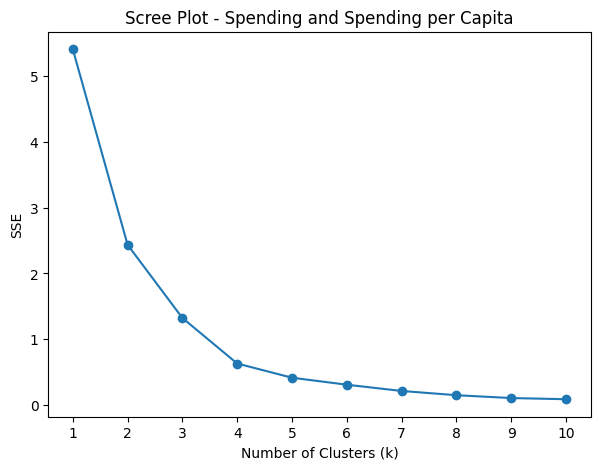

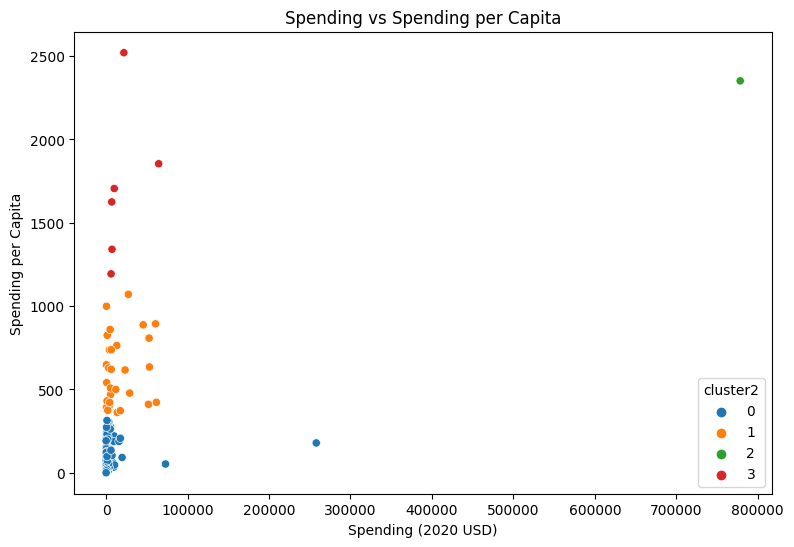

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster2                                                                   
0                      111.0    4859.185065  25405.739131       8.622460   
1                       30.0   17077.591354  20583.053357     405.790494   
2                        1.0  778397.200000           NaN  778397.200000   
3                        6.0   19443.362047  22861.507114    6095.708713   

                                                                      \
                    25%            50%            75%            max   
cluster2                                                               
0            130.010211     382.464677    2297.032353  257973.429834   
1           2294.039665    5857.060906   26296.001003   61712.537169   
2         778397.200000  778397.200000  778397.200000  778397.200000   
3           7023.251766    8624.225

In [77]:
print("-- Q2.2 - Determine optimal k for spending --")

# select the variables
cols2 = ["Spending (2020 USD)", "Spending per Capita"]

# Normalize the variables
scaler = MinMaxScaler()
X2 = scaler.fit_transform(df[cols2])

# xreate scree plot
sse = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=100, n_init=10)
    km.fit(X2)
    sse.append(km.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), sse, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("SSE")
plt.title("Scree Plot - Spending and Spending per Capita")
plt.xticks(range(1, 11))
plt.show()

# choose num clusters based on scree plot
k2 = 4

# run K-means
km2 = KMeans(n_clusters=k2, random_state=100, n_init=10)
df["cluster2"] = km2.fit_predict(X2)

# scatterplot
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster2",
    palette="tab10"
)

plt.title("Spending vs Spending per Capita")
plt.xlabel("Spending (2020 USD)")
plt.ylabel("Spending per Capita")
plt.show()

# describe table by cluster
print(df.groupby("cluster2")[cols2].describe())

# average spending by cluster
print(df.groupby("cluster2")[cols2].mean())

# number of countries in each cluster
print(df["cluster2"].value_counts())

# find the United States
print(df[df["Country"].str.contains("United States", case=False, na=False)]
      [["Country", "cluster2"] + cols2])

# see which countries are in each cluster
for cluster in sorted(df["cluster2"].unique()):
    print("\nCluster", cluster)
    print(df[df["cluster2"] == cluster]["Country"].tolist())
    
text = "The clusters seem to be separated based on how much a country spends on its military and how much they spend per person. I feel like most countries with lower spending would be grouped together, and then countries with a huge military budget or high per-person spending would be in different clusters. The United States has one of the largest military budgets, so it makes sense for it to be towards the far right of the scatter plot and probably separated from all the other countries. I think, overall, this clustering really helps show the difference between the countries that spend a lot overall and countries that spend a lot relative to their specific population."

print("\n".join(textwrap.wrap(text, width=80)))

-- Q2.3 - Determine optimal k for government spending and GDP --


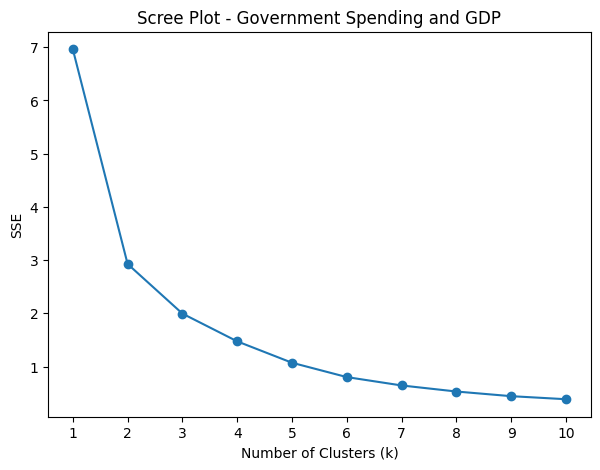

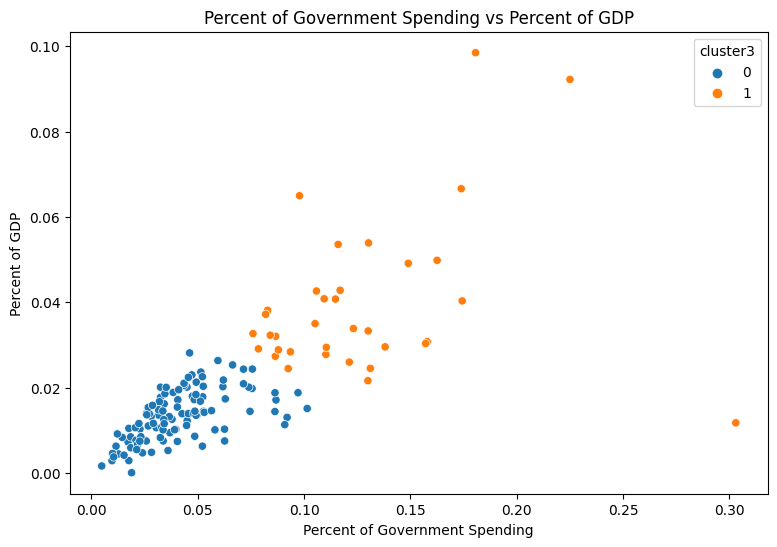

         Percent of Government Spending                                \
                                  count      mean       std       min   
cluster3                                                                
0                                 113.0  0.041394  0.020681  0.004896   
1                                  35.0  0.126456  0.046209  0.076005   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster3                                                                    
0         0.026783  0.038486  0.051496  0.101501          113.0  0.013481   
1         0.093093  0.116052  0.143584  0.303027           35.0  0.039433   

                                                                      
               std       min       25%       50%       75%       max  
cluster3                                                              
0         0.005966  0.000054  0.009

In [78]:
print("-- Q2.3 - Determine optimal k for government spending and GDP --")

# select the variables
cols3 = ["Percent of Government Spending", "Percent of GDP"]

# normalize the variables
scaler = MinMaxScaler()
X3 = scaler.fit_transform(df[cols3])

# create scree plot
sse = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=100, n_init=10)
    km.fit(X3)
    sse.append(km.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), sse, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("SSE")
plt.title("Scree Plot - Government Spending and GDP")
plt.xticks(range(1, 11))
plt.show()

# choose number of clusters based on scree plot
k3 = 2

# run K-means
km3 = KMeans(n_clusters=k3, random_state=100, n_init=10)
df["cluster3"] = km3.fit_predict(X3)

# scatterplot
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster3",
    palette="tab10"
)

plt.title("Percent of Government Spending vs Percent of GDP")
plt.xlabel("Percent of Government Spending")
plt.ylabel("Percent of GDP")
plt.show()

# describe table by cluster
print(df.groupby("cluster3")[cols3].describe())

# average values by cluster
print(df.groupby("cluster3")[cols3].mean())

# number of countries in each cluster
print(df["cluster3"].value_counts())

# find the United States
print(df[df["Country"].str.contains("United States", case=False, na=False)]
      [["Country", "cluster3"] + cols3])

# see which countries are in each cluster
for cluster in sorted(df["cluster3"].unique()):
    print("\nCluster", cluster)
    print(df[df["cluster3"] == cluster]["Country"].tolist())
    
text = "This time, the clustering focused more on how much of a country's government spending and GDP goes towards its military, rather than the actual amount of money spent. I would expect the countries with higher percentages to group together, and countries with smaller percentages to group together. This was essentially the case I had with two clusters, since the elbow point was at k=2. A very interesting difference is that a country with a smaller military budget could still be in a high-spending cluster if a large percentage of its GDP or government spending goes towards the military. There is a core difference in what the clusters represent compared to the previous part. In part two, countries are grouped together based on the total spending and spending per person. In part three, they're grouped together based on the proportion of their resources that is devoted to the military. There is a difference between the total amount and the proportion. The United States seemed to stand out far more in Part 2 because of its massive total military budget. But in Part 3, we see that the US blends in more with the higher spending group."

print("\n".join(textwrap.wrap(text, width=80)))

-- Q2.4 - Determine optimal k for all four variables --


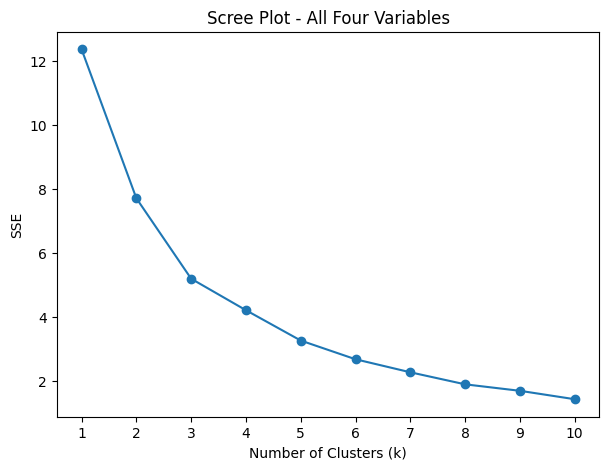

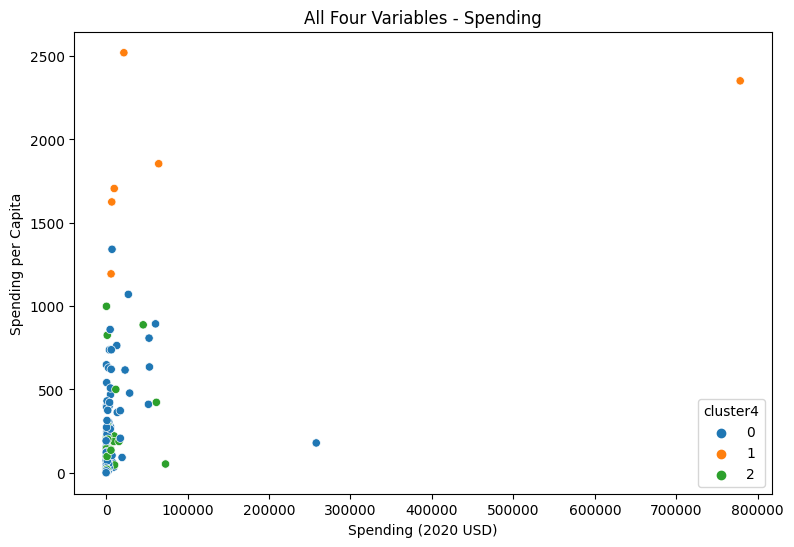

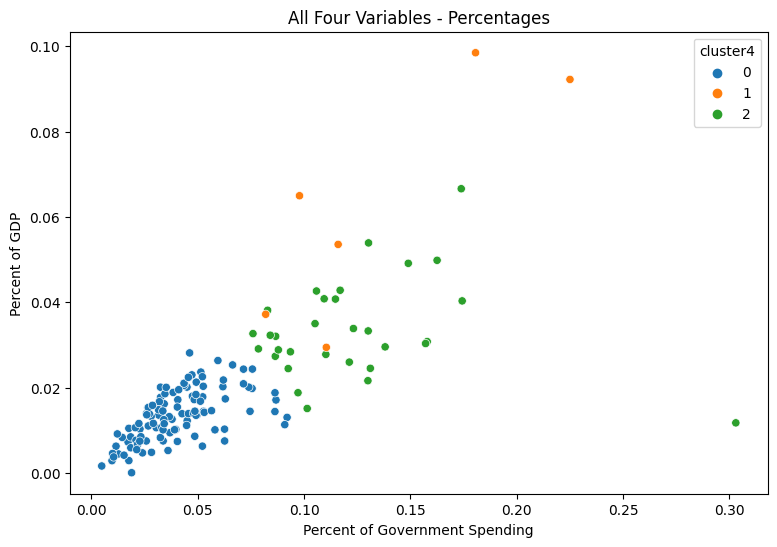

         Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster4                                                                  
0                      111.0    7086.472777   26479.379918     8.622460   
1                        6.0  147964.582042  309635.189564  6095.708713   
2                       31.0    8786.086602   17901.909108   162.373364   

                                                                  \
                  25%           50%           75%            max   
cluster4                                                           
0          130.010211    567.650747   3910.107493  257973.429834   
1         7700.424616  15897.570598  53872.942442  778397.200000   
2          467.787851   1404.787234   7739.166193   72937.064048   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...             

In [79]:
print("-- Q2.4 - Determine optimal k for all four variables --")

# select all 4 variables
cols4 = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

# normalize the variables
scaler = MinMaxScaler()
X4 = scaler.fit_transform(df[cols4])

# create scree plot
sse = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=100, n_init=10)
    km.fit(X4)
    sse.append(km.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), sse, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("SSE")
plt.title("Scree Plot - All Four Variables")
plt.xticks(range(1, 11))
plt.show()

# choose number of clusters based on scree plot
k4 = 3

# run K-means
km4 = KMeans(n_clusters=k4, random_state=100, n_init=10)
df["cluster4"] = km4.fit_predict(X4)

# scatterplot for spending variables
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster4",
    palette="tab10"
)

plt.title("All Four Variables - Spending")
plt.xlabel("Spending (2020 USD)")
plt.ylabel("Spending per Capita")
plt.show()

# scatterplot for percentage variables
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster4",
    palette="tab10"
)

plt.title("All Four Variables - Percentages")
plt.xlabel("Percent of Government Spending")
plt.ylabel("Percent of GDP")
plt.show()

# describe table by cluster
print(df.groupby("cluster4")[cols4].describe())

# average values by cluster
print(df.groupby("cluster4")[cols4].mean())

# number of countries in each cluster
print(df["cluster4"].value_counts())

# find the United States
print(df[df["Country"].str.contains("United States", case=False, na=False)]
      [["Country", "cluster4"] + cols4])

# compare clusters from Parts 2 and 4
print("\nPart 2 vs Part 4:")
print(pd.crosstab(df["cluster2"], df["cluster4"]))

# compare clusters from Parts 3 and 4
print("\nPart 3 vs Part 4:")
print(pd.crosstab(df["cluster3"], df["cluster4"]))

# see which countries are in each cluster
for cluster in sorted(df["cluster4"].unique()):
    print("\nCluster", cluster)
    print(df[df["cluster4"] == cluster]["Country"].tolist())

text = "By using all four variables, we have a lot more to work with. Instead of only looking at the size of the military budget or the percentage of a country's resources spent on military, it considers both. I would expect a few countries to change their clusters compared to parts two and three, since the algorithm is considering more characteristics. For example, if there's a country with a large military budget, it might not necessarily have a high percentage of GDP spent on defense. I think using all four variables could give a more complete picture of military spending, but the clusters may also become harder to interpret because there are more factors involved."

print("\n".join(textwrap.wrap(text, width=80)))

In [80]:
print("-- Q2.5 - kMC Useful Patterns --")

text = "I certainly think that k-means clustering was useful for finding patterns in military spending. It really showed that countries can have very different spending patterns based on what variables we specifically take a look at. Some countries may spend a great amount of money overall. Other countries may spend a large percentage of their GDP or government budget on defense. For example, a country with a massive amount of money could spend a very large amount of money on the military, but it only amounts to a very small proportion of their overall spending. On the other hand, a government with a much lower GDP or government budget may spend a great portion of that budget on the military. We see a great example of this with China and Oman, where China substantially far more on its military than Oman, but Oman devotes a much larger proportion of its GDP and government budget to defense. It's also interesting to see how changing the variables can change how the countries are grouped together. This shows that there isn't necessarily one single way to categorize military spending. Overall, I really find k-means a useful way to identify similarities and differences between countries, but it doesn't really explain why countries do spend the amounts that they might."

print("\n".join(textwrap.wrap(text, width=80)))

-- Q2.5 - kMC Useful Patterns --
I certainly think that k-means clustering was useful for finding patterns in
military spending. It really showed that countries can have very different
spending patterns based on what variables we specifically take a look at. Some
countries may spend a great amount of money overall. Other countries may spend a
large percentage of their GDP or government budget on defense. For example, a
country with a massive amount of money could spend a very large amount of money
on the military, but it only amounts to a very small proportion of their overall
spending. On the other hand, a government with a much lower GDP or government
budget may spend a great portion of that budget on the military. We see a great
example of this with China and Oman, where China substantially far more on its
military than Oman, but Oman devotes a much larger proportion of its GDP and
government budget to defense. It's also interesting to see how changing the
variables can change how t

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** e04ed2cd32511cc83ad035bbefdfd0ee2a2abf83
- **AI tool and model used:** ChatGPT GPT-6 Astra

### *Prompts used

1. Hello, I have given you access to my assignment A4 for my DS 3001 course. This assignment is a k-means clustering assignment. Please pay attention to the file, "notebook.ipynb." I have completed Phase 1 on my own. Please firstly analyze the problems being asked for Phase 1. Understand what I was supposed to do and the associated data in the /data directory. Afterwards, examine the code I wrote and the associated output to my code. After completely reviewing everything for Phase 1, you will be giving me revisions for Phase 2. Based on the questions, code, and output for Phase 1, what are the revisions you suggest to be incorporated in my code? Please identify mistakes, inconsistencies, and any possible fix you can give me to ensure my code and its output is efficient and correct.
2. Can you please view the code and output for Phase 2 that I created based on your revisions and verify that the revisions were all properly implemented and the overall code structure and accuracy is far better now? Please feel free to run the code yourself too to make sure everything works properly.

### *AI-proposed changes


1. **Q1.1–Q1.2: Keep the simulation and improve plot comparability.**

   The five datasets are correctly generated, and your interpretation that increasing noise causes greater overlap is correct. The assignment’s reference to “four datasets” is a typo.

   Use common axis limits, consistent group colors, and equal x/y aspect ratios across the scatterplots. Keep the supplied data-generation function: resetting the seed ensures the same underlying random draws are scaled by different noise levels.

2. **Q1.3: Improve the scree-plot comparison and specify multiple initializations.**

   Put all five scree curves on one labeled plot, or use subplots with shared vertical limits. Independently scaled axes make inertia differences harder to compare.

   Set `n_init=10` explicitly in Q1’s `KMeans` calls, matching Q2:

   `KMeans(n_clusters=k, random_state=100, n_init=10)`

3. **Q1.4: Refine the elbow explanation and correct the existing AI suggestion.**

   Explain that inertia is the sum of squared distances from observations to their assigned cluster centers. The elbow suggests a useful tradeoff, not a uniquely optimal k.

   At low noise, three centers capture the three generating groups; additional centers mainly subdivide those groups. At high noise, the generating groups still number three, but overlap makes them harder to recover.

   Reject the existing Phase 2 claim that Q1.4’s final paragraph is missing from its saved output: it is present in the current notebook. Still run the completed Phase 2 solution from a fresh kernel and save its regenerated outputs.

4. **Q2.1: Document the successful cleaning more explicitly.**

   The CSV contains 173 rows for 2020. Dropping incomplete rows leaves 148 unique countries, matching the assignment.

   Print the before/after counts, check missing values and duplicate countries, and remove the unused `index` column. Continue explicitly selecting clustering features so identifiers and existing cluster labels are excluded.

   Pandas already reads the four spending variables as numeric. Removing commas, currency symbols, and percent symbols is defensive rather than necessary for this file.

   Useful checks include `len(df) == 148`, `df["Country"].is_unique`, no missing feature values, and finite numeric values.

5. **Q2.2–Q2.4: Justify the selected cluster counts.**

   Your choices of `k2=4`, `k3=2`, and `k4=3` are defensible from the saved scree plots, but explain them explicitly.

   Q2.2 shows substantial reductions through approximately k=4, followed by smaller improvements. Q2.3 has its largest decrease from k=1 to k=2, although further improvements remain. Q2.4 bends around k=3, but its elbow is less decisive.

   Describe these as selected values rather than conclusively optimal values. Comparing nearby choices or adding silhouette scores is optional supporting analysis.

6. **Q2.3–Q2.4: Clarify percentage formatting and spending units.**

   The percentage columns contain fractions. The U.S. values `0.037179` and `0.081976` represent approximately 3.72% of GDP and 8.20% of government spending.

   Format percentage plot axes with `PercentFormatter(xmax=1)`, or multiply display-only copies by 100 and label them accordingly. This is a presentation correction; min–max scaling already handles the stored fractions correctly.

   Verify the total-spending multiplier against dataset documentation before labeling values as dollars or millions of dollars. The local README does not establish that unit.

7. **Q2.2: Replace speculative statements with observed results.**

   Your saved output shows cluster sizes of 111, 30, 1, and 6 for labels 0–3. Their mean spending per capita is approximately 80.06, 607.48, 2,351.63, and 1,706.72, respectively.

   The United States is definitively the only member of cluster 2, rather than “probably” separated.

   Cluster 0 includes China and India, so describing every member as a low-total-spending country would be misleading. Low average per-capita spending is a more accurate characterization.

   Explain that min–max scaling preserves skewness. Extreme values can compress differences among other observations even after normalization.

8. **Q2.3: Make the comparison numerical.**

   The two clusters contain 113 and 35 countries. Their average military shares are approximately:

   | Saved cluster label | Countries | Government-spending share | GDP share |
   |---|---:|---:|---:|
   | 0 | 113 | 4.14% | 1.35% |
   | 1 | 35 | 12.65% | 3.94% |

   The United States belongs to the higher-burden cluster alongside 34 other countries.

   Describe the clusters as lower- and higher-burden groups on average. Membership does not imply that every country is especially high or low on both measures.

9. **Q2.4: Interpret the existing cross-tabulations directly.**

   The four-variable clusters contain 111, 6, and 31 countries.

   The six-country cluster contains Israel, Kuwait, Oman, Saudi Arabia, Singapore, and the United States. Of Q2.3’s 35 higher-burden countries, six enter this cluster and 29 enter the 31-country cluster. Equatorial Guinea and Taiwan supply that cluster’s remaining two members.

   Replace statements that countries “might” change groups with these observed membership changes.

   Cluster numbers are arbitrary labels, so compare membership and profiles rather than matching label numbers across models. Also explain that the two scatterplots are projections of a four-variable model; neither displays every dimension used for clustering.

10. **Make the summary tables readable and retain medians.**

    The four-variable `.describe()` output is truncated. Display each feature’s grouped summary separately or temporarily expand pandas’ display settings.

    Retain means, medians, and counts because spending is highly skewed. For example, Q2.2 cluster 0 has mean total spending of approximately 4,859 but median spending of only 382, in the dataset’s stored units.

    The singleton U.S. cluster’s `NaN` standard deviation is expected, since sample standard deviation is undefined for one observation.

11. **Q2.5: Strengthen the conclusion and reduce repeated code.**

    Support the China–Oman comparison with observed values: military spending represents approximately 1.80% of GDP for China versus 9.85% for Oman, despite China having much larger total military spending.

    Retain the conclusion that clustering describes spending patterns without explaining their causes. Note that results depend on the chosen variables, scaling, and cluster count; using all four variables does not automatically produce a better result.

    Factor repeated scree-plot fitting into a helper that returns fitted models and inertia values. Reuse the selected model instead of fitting it again. This mainly improves organization, since performance is not a major concern for this small dataset.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | **Accept** / modify / reject | I think the LLM is telling me to remain aware of the typo in the assignment and make sure that, for the graphs, consistency is maintained. I definitely agree that common axis limits, consistent group colors, and equal x/y aspect ratios should be maintained across the scatter plots. I think, overall, ensuring that there's proper plot comparability is important, and I completely agree with this change  |
| 2 | Accept / **modify** / reject | I think having a graph displaying all of the scree plots together on one plot is a very good idea, but I don't want to replace the individual plots. Seeing them plotted individually makes them easier to look at on their own rather than jumbled together with several other plots. I'd like to keep all the individual plots, but also add an additional plot that contains all of the previous plots combined.  |
| 3 | **Accept** / modify / reject | I think this is a very meaningful change to properly explain the intuition behind the elbow. I think I could have been a little more descriptive about what inertia is and what the elbow suggests. |
| 4 | **Accept** / modify / reject | More documentation is always better so I certainly think that's a good idea. Highlighting how the cleaning went in a more discrete manner would be very helpful to those who look at my results. |
| 5 | **Accept** / modify / reject | I think it's a very good idea to explain the k values properly. I should explain how they involve the elbow point or a similar explanation. |
| 6 | **Accept** | I agree that the percentages should be easier to read. For example, 0.037179 means 3.72%. I will fix the labels and check the spending units. |
| 7 | **Accept** | I should explain what my results show instead of making guesses. The US is alone in cluster 2, and cluster 0 includes China and India, so not every country in it has low total spending. |
| 8 | **Accept** | Using the actual numbers will make my comparison clearer. The 2 clusters have 113 and 35 countries, and the US is in the group with higher average military spending shares. |
| 9 | **Accept** | I should explain the comparisons I already calculated. The 4 variable clusters have 111, 6, and 31 countries. I will describe how membership changes and remember that cluster numbers are just labels. |
| 10 | **Accept** | Some of my summary table is a bit cut off. I will display each variable separately and keep the means, medians, counts. The missing standard deviation for the U.S. cluster is expected because it has only one country. |
| 11 | **Accept** | I will add numbers to my China and Oman example and maybe use a helper function to reduce repeated code. I will also explain that the results depend on the variables, scaling, and k. I still need to run and check the Phase 2 code. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

-- Q1.1 - Create Datasets --

Noise = 0.125; observations = 150


,x1,x2,group
0,0.781279,0.851498,a
1,1.042835,0.931282,a
2,1.144129,0.882494,a
3,0.968445,0.896508,a
4,1.122665,1.013608,a



Noise = 0.25; observations = 150


,x1,x2,group
0,0.562559,0.702996,a
1,1.085670,0.862563,a
2,1.288259,0.764988,a
3,0.936891,0.793017,a
4,1.245330,1.027216,a



Noise = 0.5; observations = 150


...


Noise = 1.0; observations = 150


,x1,x2,group
0,-0.749765,-0.188018,a
1,1.342680,0.450254,a
2,2.153036,0.059954,a
3,0.747564,0.172068,a
4,1.981321,1.108863,a



Noise = 2.0; observations = 150


,x1,x2,group
0,-2.499531,-1.376035,a
1,1.685361,-0.099492,a
2,3.306072,-0.880092,a
3,0.495128,-0.655865,a
4,2.962642,1.217727,a


-- Q1.2 - Scatterplots --


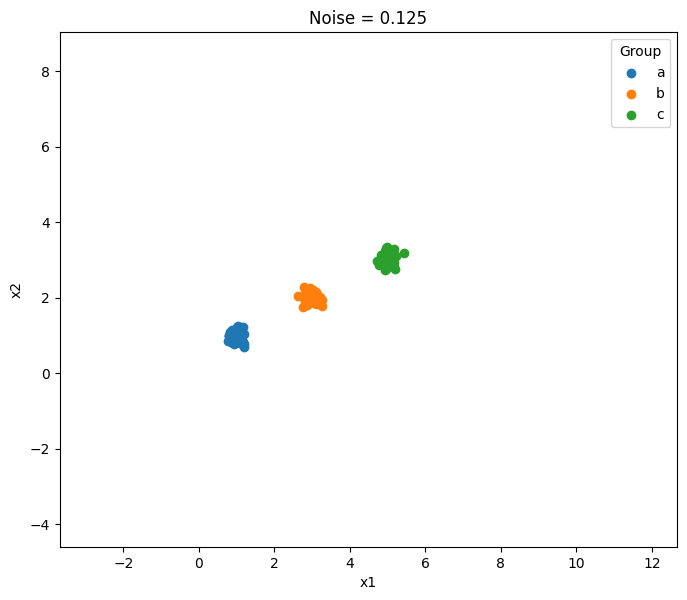

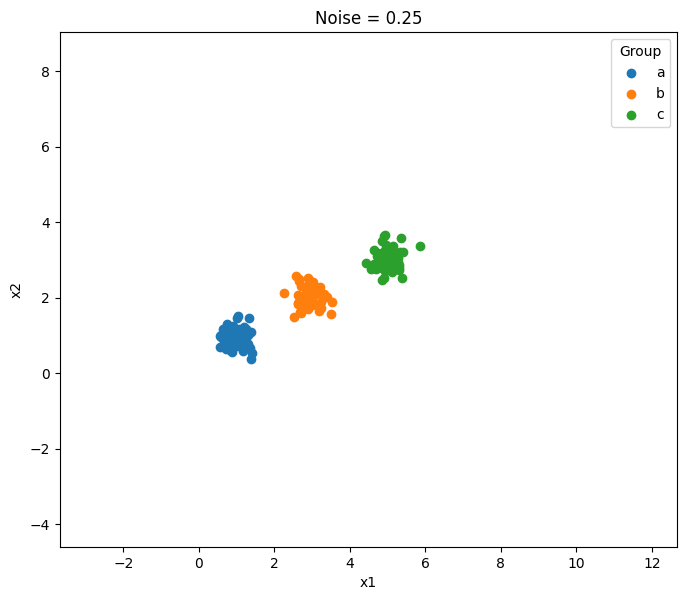

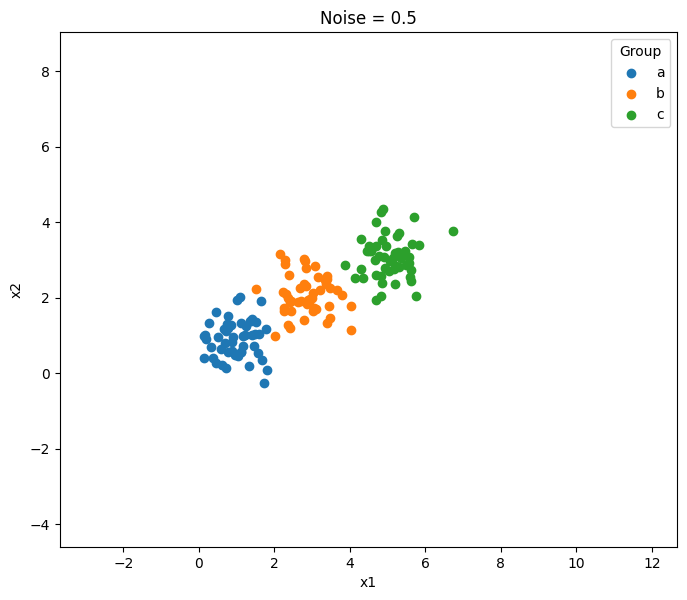

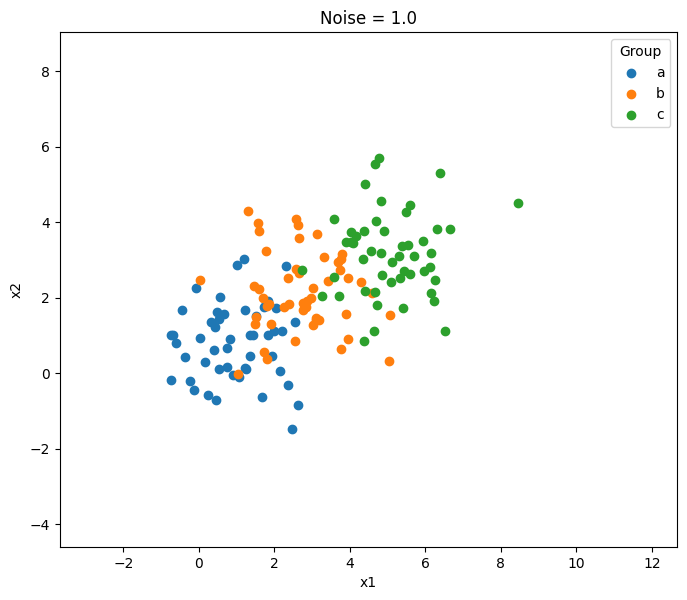

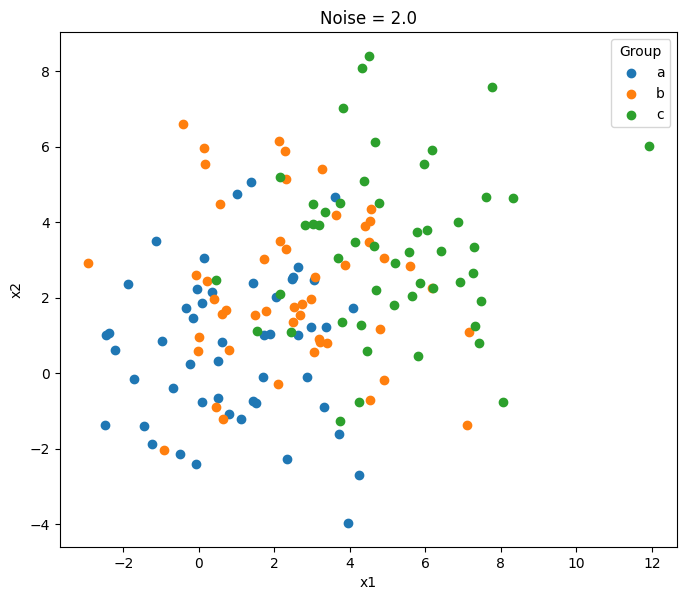

As noise increases, the points spread farther from their generating centers and the groups
overlap more. The groups are clearly separated at low noise levels, but their boundaries
become harder to distinguish at higher noise levels.

-- Q1.3 - Scree Plots --


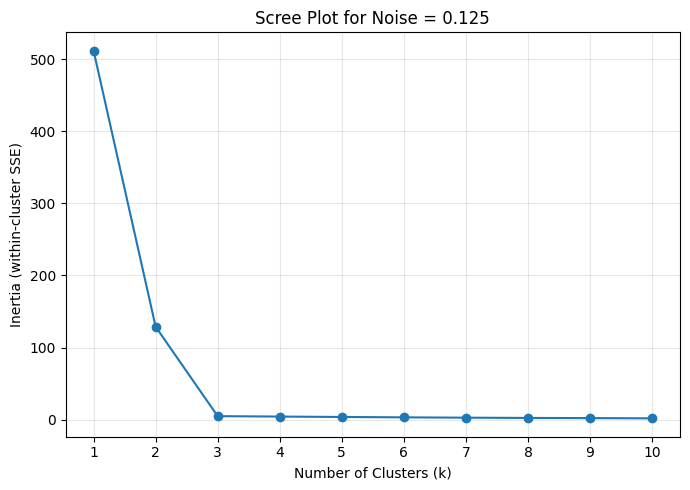

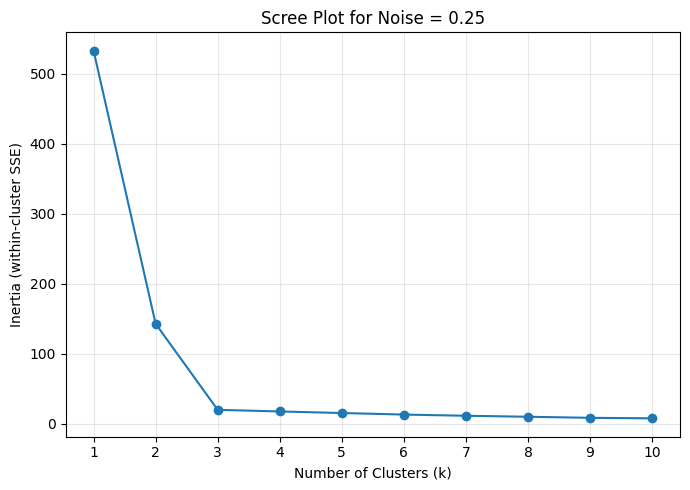

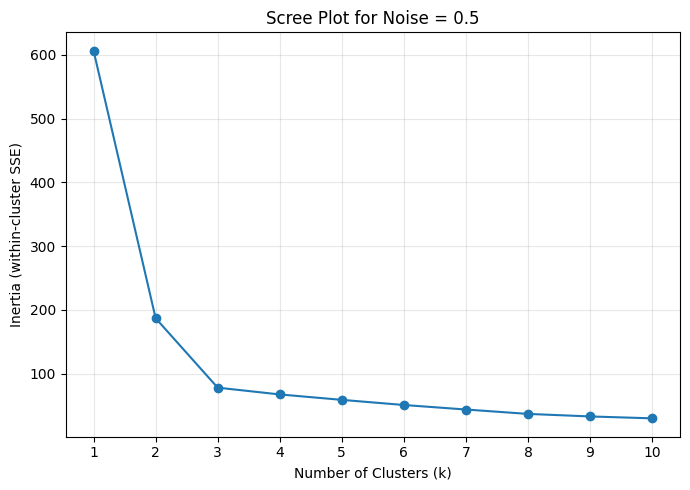

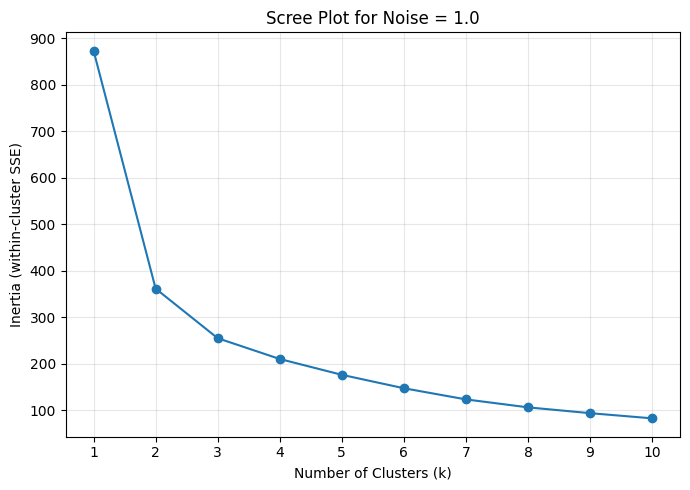

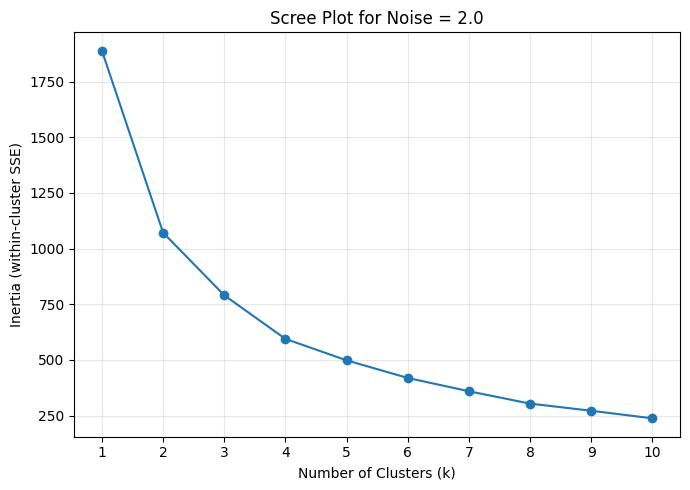

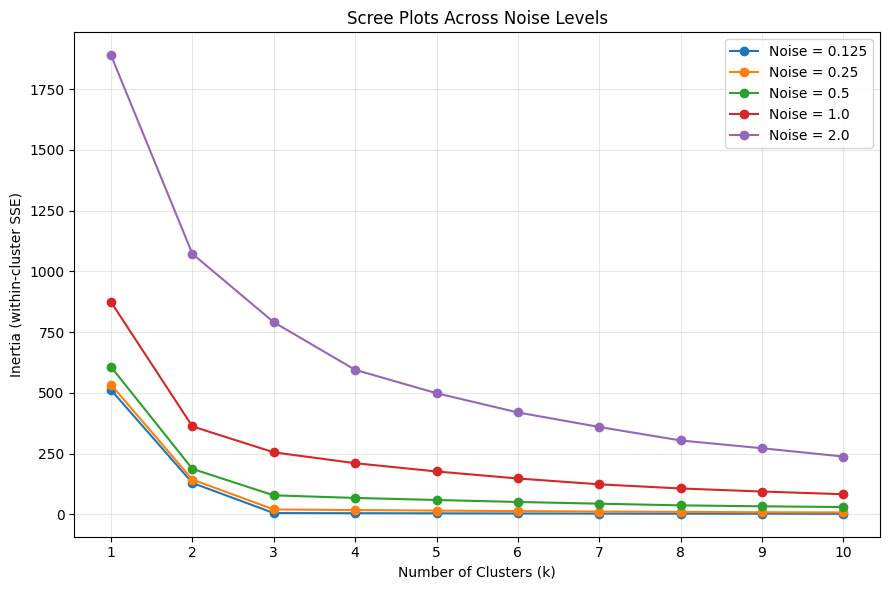

At low noise levels, the scree curves have a clear elbow around k=3. At higher noise
levels, inertia is larger at a given k and the elbow becomes less clear. The combined plot
makes the differences in inertia easier to compare, while the individual plots show each
curve in detail.

-- Q1.4 - Intuition of the Elbow --
Inertia is the sum of squared distances from each observation to its assigned cluster
center. Adding centers generally reduces inertia, but the elbow marks a point after which
the reductions become smaller. It suggests a useful balance between representing the data
and adding more clusters; it does not prove that one k is uniquely optimal.

In this simulation, three centers capture the three separated groups when noise is low.
Additional centers mainly split those groups into smaller pieces. At high noise, there are
still three generating groups, but their overlap makes them harder to recover and makes
the elbow less obvious.

-- Q2.1 - Loading and Cleaning the Data --
Row

,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
0,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
1,2020,Albania,187.433234,0.012583,0.037952,65.126211
2,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
3,2020,Angola,993.594405,0.014442,0.074624,30.231680
4,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


Filtering to 2020 gives 173 rows, and removing incomplete rows leaves 148 unique
countries. The four spending variables are numeric. The percentage columns store
fractions, so 0.037179 means 3.7179%. Only the selected spending variables will be used
for clustering.

-- Q2.2 - Spending and Spending per Capita --


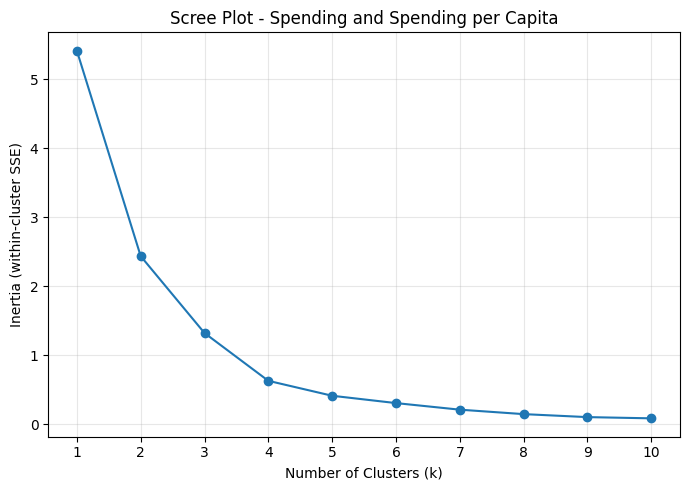

I select k=4 because the scree plot shows substantial reductions in SSE through
approximately four clusters, followed by smaller reductions. This is a reasonable elbow-
based choice, not a uniquely proven optimum.



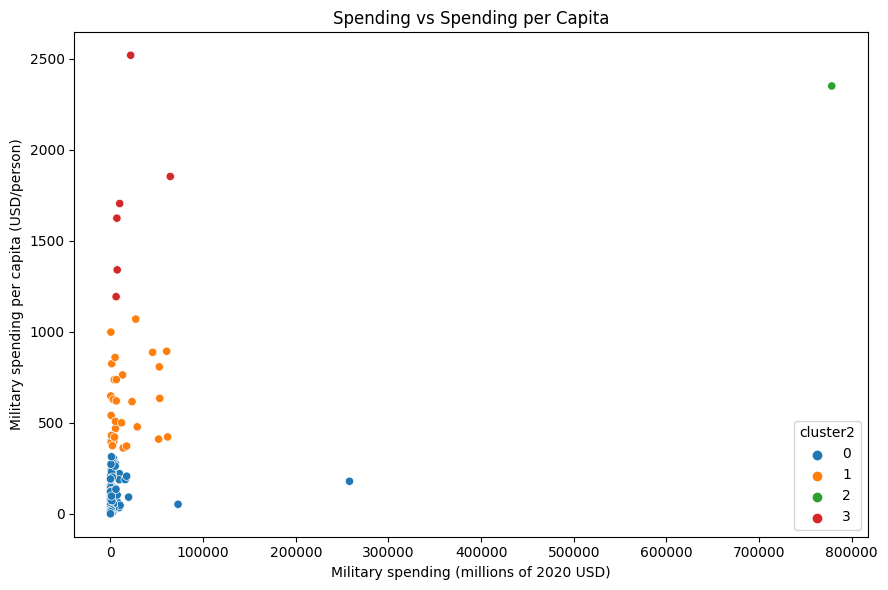


Military spending (millions of 2020 USD)


,count,mean,std,min,25%,50%,75%,max
cluster2,,,,,,,,
0,111.0,4859.185,25405.739,8.622,130.010,382.465,2297.032,257973.430
1,30.0,17077.591,20583.053,405.790,2294.040,5857.061,26296.001,61712.537
2,1.0,778397.200,NaN,778397.200,778397.200,778397.200,778397.200,778397.200
3,6.0,19443.362,22861.507,6095.709,7023.252,8624.226,18857.070,64558.400



Military spending per capita (USD/person)


,count,mean,std,min,25%,50%,75%,max
cluster2,,,,,,,,
0,111.0,80.061,83.502,0.580,14.881,47.057,125.388,314.201
1,30.0,607.479,206.929,362.467,422.208,579.005,757.329,1070.623
2,1.0,2351.632,NaN,2351.632,2351.632,2351.632,2351.632,2351.632
3,6.0,1706.722,466.376,1193.599,1412.083,1665.447,1817.220,2520.399



Cluster counts:
cluster2
0    111
1     30
2      1
3      6
Name: count, dtype: int64

United States:


,144
Country,United States of America
cluster2,2
Military spending (millions of 2020 USD),778397.2
Military spending per capita (USD/person),2351.631858



Countries in each cluster:

Cluster 0:
['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Azerbaijan', 'Bangladesh', 'Belarus', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Cape Verde', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Congo, DR', 'Congo, Republic', 'Croatia', 'Czechia', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Ethiopia', 'Fiji', 'Gabon', 'Gambia, The', 'Georgia', 'Ghana', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hungary', 'India', 'Indonesia', 'Iran', 'Iraq', 'Ireland', 'Jamaica', 'Jordan', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kyrgyz Republic', 'Lebanon', 'Lesotho', 'Liberia', 'Madagascar', 'Malawi', 'Malaysia', 'Mali', 'Malta', 'Mauritania', 'Mauritius', 'Mexico', 'Moldova', 'Mongolia', 'Montenegro', 'Morocco', 'Mozambique', 'Myanmar', 'Namibia', 'Nepal', 'Nicaragua',

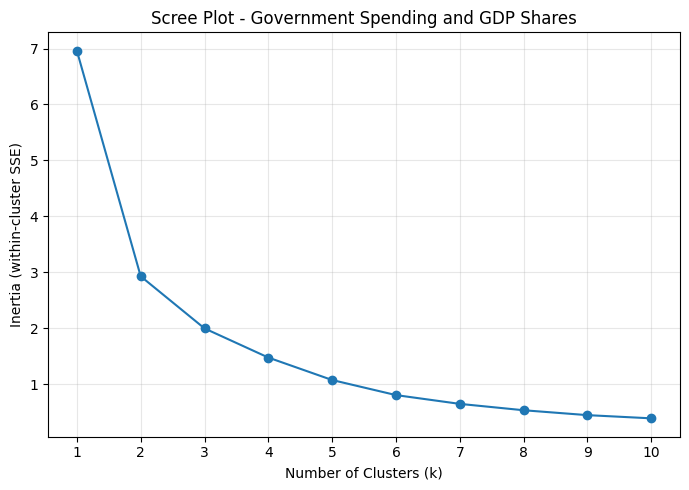

I select k=2 because the largest reduction in SSE occurs between one and two clusters,
followed by smaller reductions. The curve continues to decrease, so other choices are
possible.



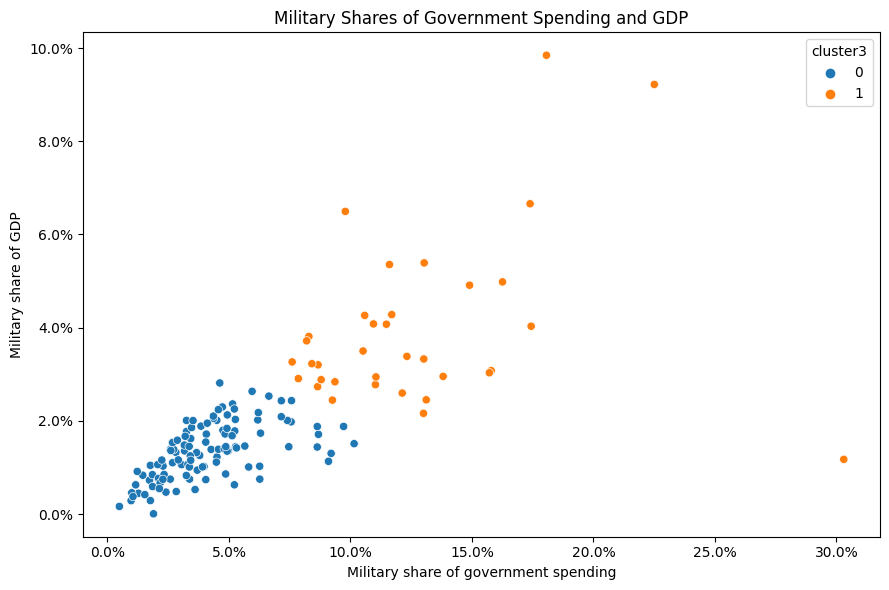


Military share of government spending (%)


,count,mean,std,min,25%,50%,75%,max
cluster3,,,,,,,,
0,113.0,4.139,2.068,0.49,2.678,3.849,5.150,10.150
1,35.0,12.646,4.621,7.60,9.309,11.605,14.358,30.303



Military share of GDP (%)


,count,mean,std,min,25%,50%,75%,max
cluster3,,,,,,,,
0,113.0,1.348,0.597,0.005,0.915,1.363,1.783,2.813
1,35.0,3.943,1.818,1.174,2.896,3.328,4.272,9.847



Cluster counts:
cluster3
0    113
1     35
Name: count, dtype: int64

United States:


,144
Country,United States of America
cluster3,1
Military share of government spending (%),8.197624
Military share of GDP (%),3.717885



Countries in each cluster:

Cluster 0:
['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Australia', 'Austria', 'Bangladesh', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Burundi', 'Cameroon', 'Canada', 'Cape Verde', 'Central African Republic', 'Chile', 'China', 'Congo, DR', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Estonia', 'Ethiopia', 'Fiji', 'Finland', 'France', 'Gabon', 'Gambia, The', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hungary', 'Indonesia', 'Ireland', 'Italy', 'Jamaica', 'Japan', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kyrgyz Republic', 'Latvia', 'Lesotho', 'Liberia', 'Lithuania', 'Luxembourg', 'Madagascar', 'Malawi', 'Malaysia', 'Malta', 'Mauritius', 'Mexico', 'Moldova', 'Mongolia', 'Montenegro', 'Mozambique', 'Nepal', 'Netherlands', 'New Zealand', 'Nicaragua', 'Niger', 'Nigeria', 'N

,Percent of Government Spending,Percent of GDP
cluster3,,
0,4.14,1.35
1,12.65,3.94


The Phase 1 results contained 113 countries in the lower-burden cluster and 35 in the
higher-burden cluster. Their average government spending shares were approximately 4.14%
and 12.65%, and their average GDP shares were 1.35% and 3.94%. The United States belonged
to the higher-burden group rather than forming its own cluster.

Compared with Q2.2, this model describes the share of a country's resources devoted to the
military rather than the amount spent. A country with a smaller total budget can therefore
belong to the higher-burden group. These descriptions refer to group averages, not to
every country being high or low on both measures.

-- Q2.4 - All Four Variables --


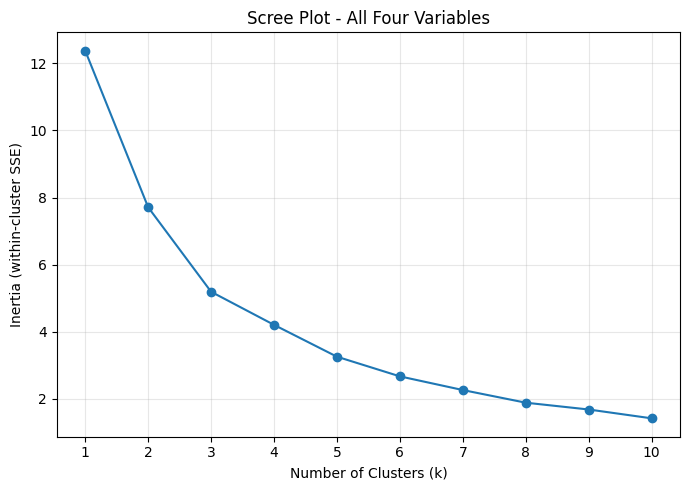

I select k=3 because the curve bends around three clusters and the reductions afterward
are smaller. This elbow is less decisive, so three clusters should be treated as a
reasonable choice rather than the only possible answer.



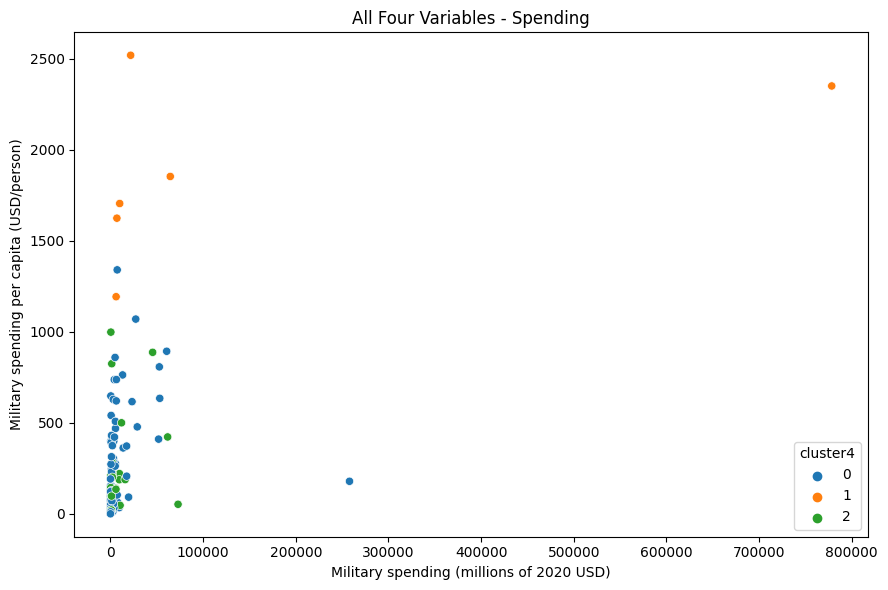

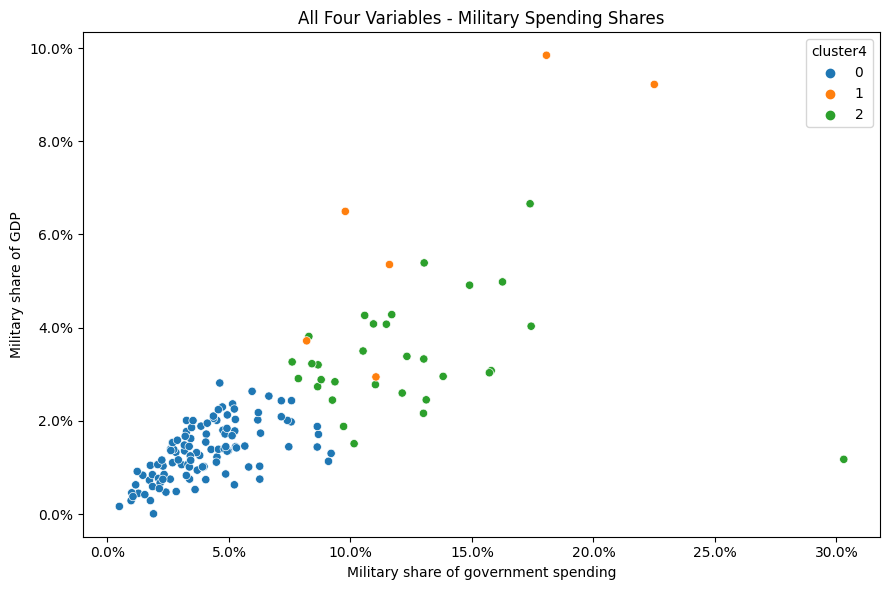


Military spending (millions of 2020 USD)


,count,mean,std,min,25%,50%,75%,max
cluster4,,,,,,,,
0,111.0,7086.473,26479.380,8.622,130.010,567.651,3910.107,257973.430
1,6.0,147964.582,309635.190,6095.709,7700.425,15897.571,53872.942,778397.200
2,31.0,8786.087,17901.909,162.373,467.788,1404.787,7739.166,72937.064



Military spending per capita (USD/person)


,count,mean,std,min,25%,50%,75%,max
cluster4,,,,,,,,
0,111.0,196.927,267.789,0.580,14.881,67.083,295.296,1341.059
1,6.0,1875.151,489.800,1193.599,1645.302,1780.060,2227.319,2520.399
2,31.0,212.689,257.842,18.297,46.486,135.460,217.334,998.966



Military share of government spending (%)


...


Part 3 vs Part 4:


cluster4,0,1,2
cluster3,,,
0,111,0,2
1,0,6,29


The Phase 1 four-variable solution had clusters of 111, 6, and 31 countries. The six-
country cluster contained Israel, Kuwait, Oman, Saudi Arabia, Singapore, and the United
States. This group had particularly high average spending per capita. The other two groups
differed more clearly in their average military spending shares.

Of the 35 higher-burden countries in Q2.3, six entered the six-country cluster and 29
entered the 31-country cluster. Equatorial Guinea and Taiwan were the other two members of
the 31-country cluster. The U.S. therefore moved from a singleton in Q2.2 to a group with
five other countries when all four variables were considered.

Cluster numbers are arbitrary labels, so comparisons should use membership and spending
profiles rather than matching label numbers. Each scatterplot displays only two dimensions
of the four-variable model, so neither plot alone shows every feature used for clustering.

-- Q2.5 - Useful Patterns --


Country,China,Oman
Spending (millions of 2020 USD),257973.43,6095.71
Spending per capita (USD/person),179.23,1193.60
Government spending share (%),4.75,18.07
GDP share (%),1.80,9.85


China spent approximately 257,973.43 million dollars on its military, compared with
6,095.71 million for Oman. However, military spending represented approximately 1.80% of
China's GDP and 9.85% of Oman's GDP. The government spending shares were approximately
4.75% and 18.07%, respectively.

K-means helps identify different military spending patterns. Large total spending, high
spending per person, and a high military share of national resources describe different
characteristics. The resulting groups depend on the chosen variables, scaling, and number
of clusters. Using all four variables provides more information, but does not
automatically make the grouping better. Clustering describes similarities and differences
without explaining why countries spend the amounts they do.



In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import textwrap

from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler


# Helpers for repeated plotting, fitting, and output.
def explain(text):
    print(textwrap.fill(text, width=90))
    print()


def fit_scree_models(X):
    models = {}
    inertia = []

    for k in range(1, 11):
        model = KMeans(
            n_clusters=k,
            random_state=100,
            n_init=10
        )
        model.fit(X)
        models[k] = model
        inertia.append(model.inertia_)

    return models, inertia


def plot_scree(inertia, title):
    plt.figure(figsize=(7, 5))
    plt.plot(range(1, 11), inertia, marker="o")
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Inertia (within-cluster SSE)")
    plt.title(title)
    plt.xticks(range(1, 11))
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# ----------------------------------------------------------
# Q1.1 — Create the five datasets
# ----------------------------------------------------------

print("-- Q1.1 - Create Datasets --")


def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([
        np.random.normal(1, noise, N),
        np.random.normal(1, noise, N)
    ])
    X2 = np.array([
        np.random.normal(3, noise, N),
        np.random.normal(2, noise, N)
    ])
    X3 = np.array([
        np.random.normal(5, noise, N),
        np.random.normal(3, noise, N)
    ])

    gdf1 = pd.DataFrame({
        "x1": X1[0, :], "x2": X1[1, :], "group": "a"
    })
    gdf2 = pd.DataFrame({
        "x1": X2[0, :], "x2": X2[1, :], "group": "b"
    })
    gdf3 = pd.DataFrame({
        "x1": X3[0, :], "x2": X3[1, :], "group": "c"
    })

    return pd.concat([gdf1, gdf2, gdf3], axis=0)


df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}

for noise, data in datasets.items():
    print(f"\nNoise = {noise}; observations = {len(data)}")
    display(data.head())


# ----------------------------------------------------------
# Q1.2 — Scatterplots with consistent axes and colors
# ----------------------------------------------------------

print("-- Q1.2 - Scatterplots --")

colors = {
    "a": "tab:blue",
    "b": "tab:orange",
    "c": "tab:green"
}

all_points = pd.concat(datasets.values(), ignore_index=True)

x_min, x_max = all_points["x1"].min(), all_points["x1"].max()
y_min, y_max = all_points["x2"].min(), all_points["x2"].max()

x_padding = 0.05 * (x_max - x_min)
y_padding = 0.05 * (y_max - y_min)

for noise, data in datasets.items():
    fig, ax = plt.subplots(figsize=(7, 6))

    for group, group_df in data.groupby("group"):
        ax.scatter(
            group_df["x1"],
            group_df["x2"],
            color=colors[group],
            label=group
        )

    ax.set_xlim(x_min - x_padding, x_max + x_padding)
    ax.set_ylim(y_min - y_padding, y_max + y_padding)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(f"Noise = {noise}")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.legend(title="Group")
    plt.tight_layout()
    plt.show()

explain(
    "As noise increases, the points spread farther from their generating "
    "centers and the groups overlap more. The groups are clearly separated "
    "at low noise levels, but their boundaries become harder to distinguish "
    "at higher noise levels."
)


# ----------------------------------------------------------
# Q1.3 — Individual scree plots plus a combined plot
# ----------------------------------------------------------

print("-- Q1.3 - Scree Plots --")

q1_inertia = {}

for noise, data in datasets.items():
    X = data[["x1", "x2"]].to_numpy()
    models, inertia = fit_scree_models(X)
    q1_inertia[noise] = inertia

    # Keep each individual plot.
    plot_scree(inertia, f"Scree Plot for Noise = {noise}")

# Add a combined plot for comparison on the same vertical scale.
plt.figure(figsize=(9, 6))

for noise, inertia in q1_inertia.items():
    plt.plot(
        range(1, 11),
        inertia,
        marker="o",
        label=f"Noise = {noise}"
    )

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (within-cluster SSE)")
plt.title("Scree Plots Across Noise Levels")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

explain(
    "At low noise levels, the scree curves have a clear elbow around k=3. "
    "At higher noise levels, inertia is larger at a given k and the elbow "
    "becomes less clear. The combined plot makes the differences in inertia "
    "easier to compare, while the individual plots show each curve in detail."
)


# ----------------------------------------------------------
# Q1.4 — Intuition of the elbow
# ----------------------------------------------------------

print("-- Q1.4 - Intuition of the Elbow --")

explain(
    "Inertia is the sum of squared distances from each observation to its "
    "assigned cluster center. Adding centers generally reduces inertia, "
    "but the elbow marks a point after which the reductions become smaller. "
    "It suggests a useful balance between representing the data and adding "
    "more clusters; it does not prove that one k is uniquely optimal."
)

explain(
    "In this simulation, three centers capture the three separated groups "
    "when noise is low. Additional centers mainly split those groups into "
    "smaller pieces. At high noise, there are still three generating groups, "
    "but their overlap makes them harder to recover and makes the elbow "
    "less obvious."
)


# ----------------------------------------------------------
# Q2.1 — Load, clean, and check the data
# ----------------------------------------------------------

print("-- Q2.1 - Loading and Cleaning the Data --")

df = pd.read_csv("data/SIPRI Military Expenditure Database.csv")
df.columns = df.columns.str.strip()

df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df = df.loc[df["Year"] == 2020].copy()

cols = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP"
]

percentage_cols = [
    "Percent of Government Spending",
    "Percent of GDP"
]

print("Rows for 2020 before cleaning:", len(df))
print("\nOriginal feature types:")
print(df[cols].dtypes)

# These replacements are defensive; this CSV is already numeric.
for col in cols:
    cleaned = (
        df[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.replace("$", "", regex=False)
        .str.replace("%", "", regex=False)
    )
    df[col] = pd.to_numeric(cleaned, errors="coerce")

print("\nMissing values before dropping incomplete rows:")
print(df.isna().sum())

rows_before = len(df)
df = df.dropna().reset_index(drop=True)
df = df.drop(columns=["index"], errors="ignore")

print("\nRows removed:", rows_before - len(df))
print("Rows retained:", len(df))
print("Unique countries:", df["Country"].nunique())
print("Duplicate countries:", df["Country"].duplicated().sum())

assert len(df) == 148
assert df["Country"].is_unique
assert df[cols].notna().all().all()
assert np.isfinite(df[cols].to_numpy()).all()

display(df.head())

explain(
    "Filtering to 2020 gives 173 rows, and removing incomplete rows leaves "
    "148 unique countries. The four spending variables are numeric. "
    "The percentage columns store fractions, so 0.037179 means 3.7179%. "
    "Only the selected spending variables will be used for clustering."
)

# The U.S. value of 778397.2 is consistent with millions of dollars:
# SIPRI reports approximately $778 billion for 2020.
# Source: https://www.sipri.org/yearbook/2021/08
# The local CSV itself does not document the multiplier.
labels = {
    "Spending (2020 USD)": "Military spending (millions of 2020 USD)",
    "Spending per Capita": "Military spending per capita (USD/person)",
    "Percent of Government Spending": "Military share of government spending",
    "Percent of GDP": "Military share of GDP"
}


def plot_clusters(data, x, y, cluster_col, title):
    fig, ax = plt.subplots(figsize=(9, 6))

    sns.scatterplot(
        data=data,
        x=x,
        y=y,
        hue=cluster_col,
        palette="tab10",
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel(labels[x])
    ax.set_ylabel(labels[y])

    if x in percentage_cols:
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    if y in percentage_cols:
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

    plt.tight_layout()
    plt.show()


def show_cluster_results(data, cluster_col, features):
    # Convert percentages only in this display copy.
    shown = data[["Country", cluster_col] + features].copy()
    display_names = {}

    for feature in features:
        if feature in percentage_cols:
            shown[feature] *= 100
            display_names[feature] = labels[feature] + " (%)"
        else:
            display_names[feature] = labels[feature]

    shown = shown.rename(columns=display_names)
    shown_features = [display_names[feature] for feature in features]

    # One feature at a time prevents the wide describe table being cut off.
    for feature in shown_features:
        print(f"\n{feature}")
        display(
            shown.groupby(cluster_col)[feature]
            .describe()
            .round(3)
        )

    print("\nCluster counts:")
    print(data[cluster_col].value_counts().sort_index())

    print("\nUnited States:")
    display(
        shown.loc[
            shown["Country"].eq("United States of America")
        ].T
    )

    print("\nCountries in each cluster:")
    for cluster, group in data.groupby(cluster_col):
        print(f"\nCluster {cluster}:")
        print(group["Country"].tolist())


# ----------------------------------------------------------
# Q2.2 — Total spending and spending per capita
# ----------------------------------------------------------

print("-- Q2.2 - Spending and Spending per Capita --")

cols2 = ["Spending (2020 USD)", "Spending per Capita"]

scaler2 = MinMaxScaler()
X2 = scaler2.fit_transform(df[cols2])

models2, sse2 = fit_scree_models(X2)
plot_scree(sse2, "Scree Plot - Spending and Spending per Capita")

k2 = 4

explain(
    "I select k=4 because the scree plot shows substantial reductions in "
    "SSE through approximately four clusters, followed by smaller reductions. "
    "This is a reasonable elbow-based choice, not a uniquely proven optimum."
)

# Reuse the model already fitted for the scree plot.
km2 = models2[k2]
df["cluster2"] = km2.labels_

plot_clusters(
    df, cols2[0], cols2[1], "cluster2",
    "Spending vs Spending per Capita"
)
show_cluster_results(df, "cluster2", cols2)

explain(
    "The Phase 1 results had cluster sizes of 111, 30, 1, and 6 for "
    "labels 0–3. The United States was the only member of cluster 2. "
    "Cluster 0 had low average spending per capita, but it also contained "
    "China and India, so it was not simply a group of countries with "
    "small total military budgets. The regenerated tables above allow "
    "these results to be checked."
)

explain(
    "Min–max scaling puts each feature on a range from zero to one, "
    "but it does not remove skewness. Extreme spending values compress "
    "differences among most other countries. The NaN standard deviation "
    "for a one-country cluster is expected because sample standard "
    "deviation requires at least two observations."
)


# ----------------------------------------------------------
# Q2.3 — Government-spending share and GDP share
# ----------------------------------------------------------

print("-- Q2.3 - Government Spending and GDP Shares --")

cols3 = ["Percent of Government Spending", "Percent of GDP"]

scaler3 = MinMaxScaler()
X3 = scaler3.fit_transform(df[cols3])

models3, sse3 = fit_scree_models(X3)
plot_scree(sse3, "Scree Plot - Government Spending and GDP Shares")

k3 = 2

explain(
    "I select k=2 because the largest reduction in SSE occurs between "
    "one and two clusters, followed by smaller reductions. The curve "
    "continues to decrease, so other choices are possible."
)

km3 = models3[k3]
df["cluster3"] = km3.labels_

plot_clusters(
    df, cols3[0], cols3[1], "cluster3",
    "Military Shares of Government Spending and GDP"
)
show_cluster_results(df, "cluster3", cols3)

print("\nMean military shares by cluster (%):")
display(
    (df.groupby("cluster3")[cols3].mean() * 100).round(2)
)

explain(
    "The Phase 1 results contained 113 countries in the lower-burden "
    "cluster and 35 in the higher-burden cluster. Their average government "
    "spending shares were approximately 4.14% and 12.65%, and their average "
    "GDP shares were 1.35% and 3.94%. The United States belonged to the "
    "higher-burden group rather than forming its own cluster."
)

explain(
    "Compared with Q2.2, this model describes the share of a country's "
    "resources devoted to the military rather than the amount spent. "
    "A country with a smaller total budget can therefore belong to the "
    "higher-burden group. These descriptions refer to group averages, "
    "not to every country being high or low on both measures."
)


# ----------------------------------------------------------
# Q2.4 — All four variables
# ----------------------------------------------------------

print("-- Q2.4 - All Four Variables --")

cols4 = cols.copy()

scaler4 = MinMaxScaler()
X4 = scaler4.fit_transform(df[cols4])

models4, sse4 = fit_scree_models(X4)
plot_scree(sse4, "Scree Plot - All Four Variables")

k4 = 3

explain(
    "I select k=3 because the curve bends around three clusters and "
    "the reductions afterward are smaller. This elbow is less decisive, "
    "so three clusters should be treated as a reasonable choice rather "
    "than the only possible answer."
)

km4 = models4[k4]
df["cluster4"] = km4.labels_

plot_clusters(
    df, cols2[0], cols2[1], "cluster4",
    "All Four Variables - Spending"
)
plot_clusters(
    df, cols3[0], cols3[1], "cluster4",
    "All Four Variables - Military Spending Shares"
)

show_cluster_results(df, "cluster4", cols4)

print("\nPart 2 vs Part 4:")
display(pd.crosstab(df["cluster2"], df["cluster4"]))

print("\nPart 3 vs Part 4:")
display(pd.crosstab(df["cluster3"], df["cluster4"]))

explain(
    "The Phase 1 four-variable solution had clusters of 111, 6, and "
    "31 countries. The six-country cluster contained Israel, Kuwait, "
    "Oman, Saudi Arabia, Singapore, and the United States. This group "
    "had particularly high average spending per capita. The other two "
    "groups differed more clearly in their average military spending shares."
)

explain(
    "Of the 35 higher-burden countries in Q2.3, six entered the "
    "six-country cluster and 29 entered the 31-country cluster. "
    "Equatorial Guinea and Taiwan were the other two members of the "
    "31-country cluster. The U.S. therefore moved from a singleton "
    "in Q2.2 to a group with five other countries when all four "
    "variables were considered."
)

explain(
    "Cluster numbers are arbitrary labels, so comparisons should use "
    "membership and spending profiles rather than matching label numbers. "
    "Each scatterplot displays only two dimensions of the four-variable "
    "model, so neither plot alone shows every feature used for clustering."
)


# ----------------------------------------------------------
# Q2.5 — Useful patterns
# ----------------------------------------------------------

print("-- Q2.5 - Useful Patterns --")

comparison = (
    df.loc[df["Country"].isin(["China", "Oman"]), ["Country"] + cols]
    .set_index("Country")
    .copy()
)

comparison[percentage_cols] *= 100
comparison = comparison.rename(columns={
    "Spending (2020 USD)": "Spending (millions of 2020 USD)",
    "Spending per Capita": "Spending per capita (USD/person)",
    "Percent of Government Spending": "Government spending share (%)",
    "Percent of GDP": "GDP share (%)"
})

display(comparison.T.round(2))

china = df.loc[df["Country"].eq("China")].iloc[0]
oman = df.loc[df["Country"].eq("Oman")].iloc[0]

explain(
    f"China spent approximately "
    f"{china['Spending (2020 USD)']:,.2f} million dollars on its military, "
    f"compared with {oman['Spending (2020 USD)']:,.2f} million for Oman. "
    f"However, military spending represented approximately "
    f"{china['Percent of GDP'] * 100:.2f}% of China's GDP and "
    f"{oman['Percent of GDP'] * 100:.2f}% of Oman's GDP. "
    f"The government spending shares were approximately "
    f"{china['Percent of Government Spending'] * 100:.2f}% and "
    f"{oman['Percent of Government Spending'] * 100:.2f}%, respectively."
)

explain(
    "K-means helps identify different military spending patterns. "
    "Large total spending, high spending per person, and a high military "
    "share of national resources describe different characteristics. "
    "The resulting groups depend on the chosen variables, scaling, "
    "and number of clusters. Using all four variables provides more "
    "information, but does not automatically make the grouping better. "
    "Clustering describes similarities and differences without explaining "
    "why countries spend the amounts they do."
)

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

 As usual, AI gave a lot of great improvements in terms of improving the documentation and reporting part of my outcome. I understand what an important part of machine learning and data science the output is, because it's what those who didn't write the code actually look at to understand what's going on. It's important to properly tell a story and make sure everything is clear when reporting this data. I think the AI does a great job of making sure that everything that is important is not left untold. I also think it caught some situations. I really like the suggestion of the combined scatter plot, for example, as it really makes it easier to compare the different datasets. The AI also made sure I understood some important things, such as how the elbow suggests a reasonable k rather than completely proving an optimal choice. I don't think it really made any mistakes other than accidentally claiming that question 1.4's saved output didn't have a paragraph. Overall it gave me some really useful suggestions and I really appreciate how it helped to make sure I'm reporting everything as much as possible. 